# Нейросеть для предсказания калорийности блюд


Задача - обучить нейросеть, которая будет предсказывать калорийность блюд по их фотографии и текстовому описанию ингредиентов.


In [25]:
import textwrap
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch

from scripts.config import Config
from scripts.dataset import build_dataloaders
from scripts.model import DishCaloriesRegressor, train, validate
from scripts.utils import get_dataset_url, load_dish_image, parse_ingredients

RANDOM_STATE = 42

## Подготовка данных


Загружаем набор данных.


In [2]:
DATASET_URL = "https://disk.yandex.ru/d/kz9g5msVqtahiw"

download_url = get_dataset_url(DATASET_URL)

!wget -O nutrition.zip -nc "$download_url"

File 'nutrition.zip' already there; not retrieving.


Распаковываем датасет.


In [3]:
DATA_DIR = Path.cwd() / "data"

if Path(DATA_DIR).exists():
    print("Датасет уже распакован.")
else:
    with zipfile.ZipFile("nutrition.zip") as zip_archive:
        zip_archive.extractall()
        print("Датасет распакован.")

Датасет уже распакован.


Теперь посмотрим на состав датасета.


In [4]:
images = DATA_DIR.rglob("rgb.png")
images_count = sum(1 for item in images if item.is_file())

print(f"Количество фотографий блюд: {images_count}")

Количество фотографий блюд: 3490


In [5]:
DISH_CSV = "dish.csv"
INGREDIENTS_CSV = "ingredients.csv"

dishes_df = pd.read_csv(DATA_DIR / DISH_CSV, index_col="dish_id")
ingredients_df = pd.read_csv(DATA_DIR / INGREDIENTS_CSV, index_col="id")

print(f"Записей в {DISH_CSV}        : {len(dishes_df)}")
print(f"Записей в {INGREDIENTS_CSV} : {len(ingredients_df)}")

Записей в dish.csv        : 3262
Записей в ingredients.csv : 555


Всего в датасете:

- 3490 фотографий блюд,
- 3262 записи с информацией о блюдах и их состав,
- 555 записей об ингредиентах.


In [6]:
ingredients_df.head()

,ingr
id,
1,cottage cheese
2,strawberries
3,garden salad
4,bacon
5,potatoes


In [7]:
dishes_df.head()

,total_calories,total_mass,ingredients,split
dish_id,,,,
dish_1561662216,300.794281,193.0,ingr_0000000508;ingr_0000000122;ingr_000000002...,test
dish_1561662054,419.438782,292.0,ingr_0000000312;ingr_0000000026;ingr_000000002...,train
dish_1562008979,382.936646,290.0,ingr_0000000448;ingr_0000000520;ingr_000000046...,test
dish_1560455030,20.590000,103.0,ingr_0000000471;ingr_0000000031;ingr_0000000347,train
dish_1558372433,74.360001,143.0,ingr_0000000453,train


Ингредиенты закодированы идентификаторами, которые нужно заменить на названия продуктов. Убираем префикс; оставшееся число будет номером ингредиента в `ingredients.csv`.


In [8]:
dishes_df["ingredients"] = dishes_df["ingredients"].apply(
    parse_ingredients, ingredients_map=ingredients_df["ingr"].to_dict()
)
dishes_df.head()

,total_calories,total_mass,ingredients,split
dish_id,,,,
dish_1561662216,300.794281,193.0,"apple, bok choy, brown rice, garlic, lemon jui...",test
dish_1561662054,419.438782,292.0,"apple, bok choy, garlic, green beans, lemon ju...",train
dish_1562008979,382.936646,290.0,"cabbage, caesar salad, carrot, garlic, jalapen...",test
dish_1560455030,20.590000,103.0,"baby carrots, cherry tomatoes, cucumbers",train
dish_1558372433,74.360001,143.0,deprecated,train


## EDA


In [9]:
dishes_df.info()

<class 'pandas.DataFrame'>
Index: 3262 entries, dish_1561662216 to dish_1568664931
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   total_calories  3262 non-null   float64
 1   total_mass      3262 non-null   float64
 2   ingredients     3262 non-null   str    
 3   split           3262 non-null   str    
dtypes: float64(2), str(2)
memory usage: 127.4+ KB


В датасете содержится информация о:

- калорийности блюда в килокалориях - целевая переменная,
- масса порции в граммах,
- список ингредиентов через запятую,
- название выборки (train/test).


In [10]:
dishes_df.isna().sum()

total_calories    0
total_mass        0
ingredients       0
split             0
dtype: int64

Пропусков в данных нет.


In [11]:
pd.DataFrame({
    "Количество": dishes_df["split"].value_counts(normalize=False),
    "Доля, %": dishes_df["split"].value_counts(normalize=True),
}).style.format({"Доля, %": "{:.2%}"})

,Количество,"Доля, %"
split,,
train,2755,84.46%
test,507,15.54%


Данные уже разделены в соотношении 85% к 15%: 2755 записей в train, 507 - в test.


### Ингредиенты


In [12]:
all_ingredients = (
    ingredient
    for ingredients in dishes_df["ingredients"]
    for ingredient in ingredients.split(", ")
)

ingredients_count = (
    pd
    .DataFrame(Counter(all_ingredients).items(), columns=["Ингредиент", "Количество"])
    .sort_values(by="Количество", ascending=False)
    .reset_index(drop=True)
)

ingredients_count

,Ингредиент,Количество
0,olive oil,1561
1,salt,1379
2,garlic,947
3,pepper,723
4,vinegar,713
...,...,...
194,mozzarella cheese,1
195,brown sugar,1
196,banana with peel,1
197,balsamic vinegar,1


Есть ингредиенты, которые часто встречаются, а есть те, которые используются только в одном блюде.


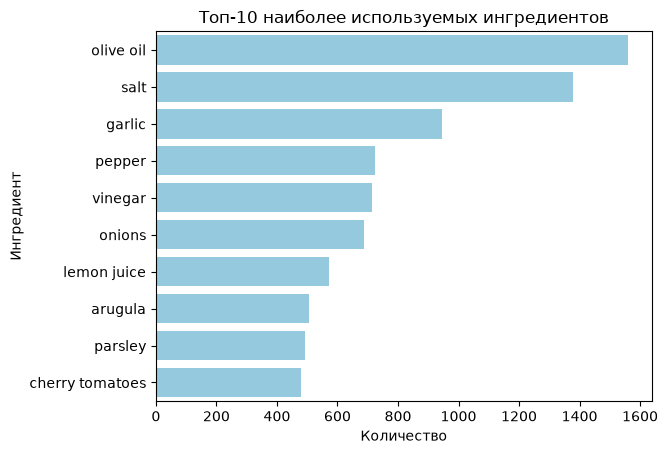

In [13]:
sns.barplot(
    data=ingredients_count.head(10),
    x="Количество",
    y="Ингредиент",
    orient="h",
    color="skyblue",
)

plt.title("Топ-10 наиболее используемых ингредиентов")
plt.show()

Чаще всего в блюдах используются приправы: оливковое масло, соль, перец, чеснок.


### Калорийность и масса порции


In [14]:
dishes_df.describe(percentiles=[0.5, 0.95, 0.99]).T

,count,mean,std,min,50%,95%,99%,max
total_calories,3262.0,255.012738,219.637570,0.0,209.110062,646.759069,918.535122,3943.325195
total_mass,3262.0,214.980074,161.497428,1.0,177.000000,500.000000,702.340000,3051.000000


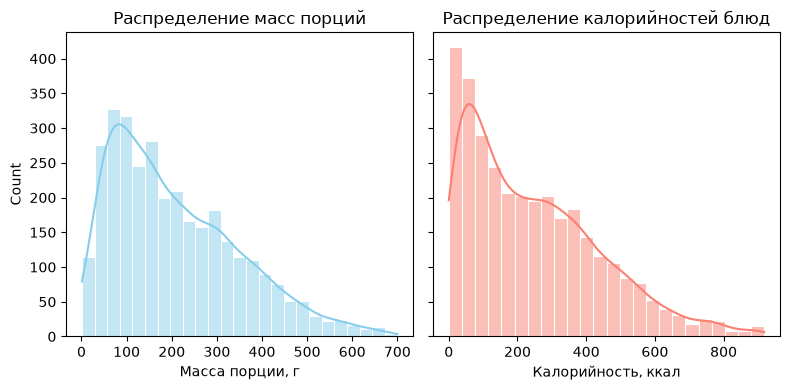

In [15]:
total_mass_q99 = dishes_df[
    dishes_df["total_mass"] < dishes_df["total_mass"].quantile(0.99)
]["total_mass"]
total_calories_q99 = dishes_df[
    dishes_df["total_calories"] < dishes_df["total_calories"].quantile(0.99)
]["total_calories"]

_, ax = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

sns.histplot(total_mass_q99, kde=True, ax=ax[0], color="skyblue", edgecolor="white")
ax[0].set_title("Распределение масс порций")
ax[0].set_xlabel("Масса порции, г")

sns.histplot(total_calories_q99, kde=True, color="salmon", edgecolor="white")
ax[1].set_title("Распределение калорийностей блюд")
ax[1].set_xlabel("Калорийность, ккал")

plt.tight_layout()
plt.show()

Средние значения для калорийности и массы порции небольшие (255 и 215 соответственно), но есть и экстремальные значения. Это говорит о том, что у распределения есть длинный хвост справа. Редкие большие значения могут искажать предсказания модели для блюд с большой калорийностью.


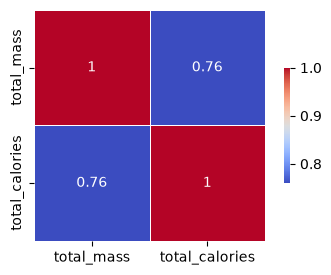

In [16]:
mass_calories_corr = dishes_df[["total_mass", "total_calories"]].corr()

plt.figure(figsize=(5, 3))

sns.heatmap(
    mass_calories_corr,
    cmap="coolwarm",
    annot=True,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.5},
)

plt.show()

Корреляция между массой порции и количеством калорий равна 0.76 - это указывает на сильную положительную связь между значениями, т.е. с помощью массы можно хорошо предсказывать калорийность.


### Фотографии блюд


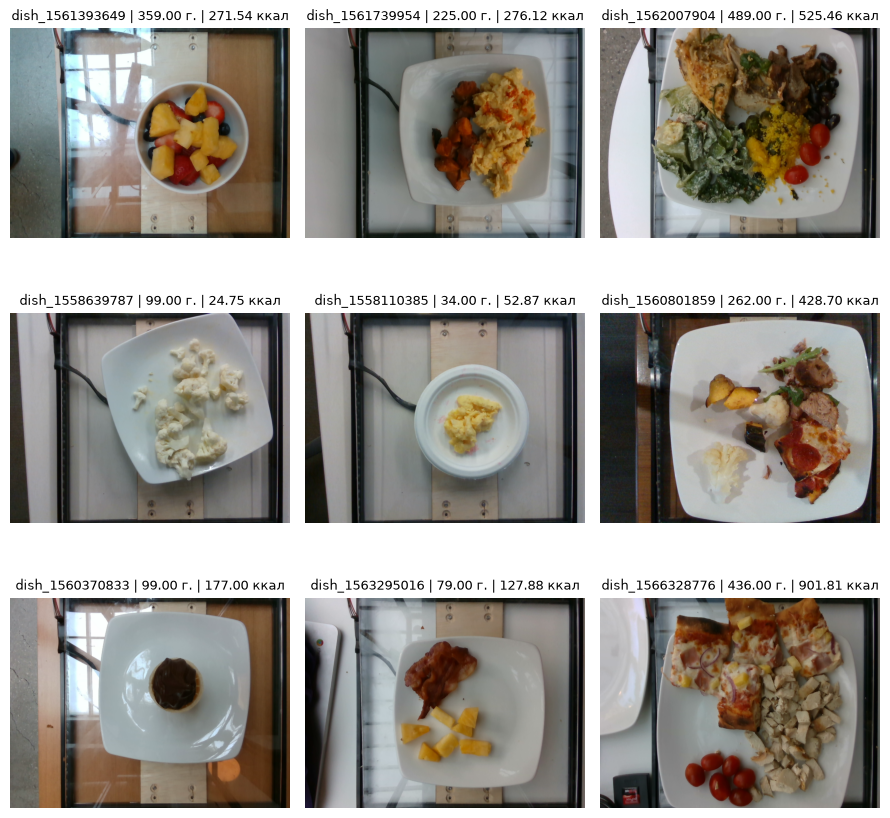

In [17]:
dish_ids = dishes_df.sample(9, random_state=RANDOM_STATE).index.to_list()

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(9, 9))

axes = axes.flatten()

for ax, dish_id in zip(axes, dish_ids):
    img = load_dish_image(dish_id)

    total_calories, total_mass = dishes_df.loc[
        dish_id, ["total_calories", "total_mass"]
    ]

    title = f"{dish_id} | {total_mass:.2f} г. | {total_calories:.2f} ккал"

    ax.imshow(img)
    ax.set_title(title, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

Фотографии блюд с различным приближением, положением камеры и освещением - нужно учесть при аугментации.


### Выводы по EDA

В датасете предоставлена информация о 3262 блюдах: изображение, текстовое перечисление ингредиентов, масса порции и калорийность (целевая переменная). Пропусков в данных нет. Разделение на train/test выборки уже сделано: 2755 в train, 507 в test.

Распределение для калорийности скошено вправо, среднее 255 ккал, а наибольшее - 3943 ккал. 99% всех значений не превышают 918 ккал. Поэтому, скорее всего модель предсказания может недооценивать очень калорийные блюда. Также, между калорийностью и размером порции есть сильная положительная связь, значит, размер порции будет полезным признаком для модели.

Среди наиболее часто встречающихся ингредиентов есть высококалорийные, так и низкокалорийные ингредиенты. Например, оливковое масло используют в половине всех представленных блюд, но в данных не указывается его количество, поэтому использование этого признака не даёт модели однозначного сигнала для увеличения предсказанного значения. Низкокалорийные ингредиенты также часто используются в блюдах, поэтому из-за них модель также может "повысить" итоговое значение, хотя они почти не вносят свой вклад.


### Решение задачи предсказания калорийности блюда

В этой задаче у нас имеются различные данные (числовые, текстовые) и изображения. Значит, нужно реализовать мультимодальную модель, которая использует их все:

- для изображений используем предобученную модель `EfficientNetV2-M`, которая может извлечь визуальные признаки из фотографий блюд,
- для кодирования признаков по текстовому составу ингредиентов используем модель `all-MiniLM-L6-v2`,
- добавляем проекционные слои для приведения размерностей к общему значению,
- числовые значения масс порций нормализуем с помощью `StandardScaler`,
- полученные эмбеддинги конкатенируем и подаём в линейный слой, которые будет предсказывать калорийность.

Изображения нужно аугментировать перед обучением:

- `Resize` - меняем размеры изображения на подходящие модели
- `HorizontalFlip`/`VerticalFlip`/`RandomRotate90` - учитываем разное положение камеры
- `RandomBrightnessContrast` - разное освещение
- `Normalize` - по тем значениям, которые использовались в модели

Данных не очень много, поэтому нужно учесть вероятность переобучения и вовремя остановиться. Для измерения качества обучения используем MAE. Требование - MAE меньше 50 ккал на тестовой выборке.


## Обучение модели


Код пайплайна обучения модели вынесен в отдельные `.py` файлы в `scripts/`:

- `config.py` содержит параметры конфигурации
- `dataset.py` загружает данные и формирует батчи для обучения
- модель PyTorch и код для её обучения и валидации - в `model.py`


In [18]:
config = Config()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

Устройство: cuda


Загружаем train/val/test выборки данных.


In [19]:
data = build_dataloaders(dishes_df, config)

train_loader = data.train
val_loader = data.val
test_loader = data.test

print("Количество батчей в:")
print(f"train - {len(train_loader)}")
print(f"val   - {len(val_loader)}")
print(f"test  - {len(test_loader)}")

Количество батчей в:
train - 620
val   - 69
test  - 127


Обучаем модель и сохраняем лучший результат по метрике MAE.


In [20]:
model, history = train(train_loader, val_loader, config, device)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Эпоха 1/15 | train_loss: 97.5886 | val_mae: 79.8120
Сохраняем модель с MAE 79.8120 в checkpoints\best_model.pt
Эпоха 2/15 | train_loss: 72.3052 | val_mae: 61.7044
Сохраняем модель с MAE 61.7044 в checkpoints\best_model.pt
Эпоха 3/15 | train_loss: 65.2880 | val_mae: 62.1333
Эпоха 4/15 | train_loss: 62.4700 | val_mae: 51.0693
Сохраняем модель с MAE 51.0693 в checkpoints\best_model.pt
Эпоха 5/15 | train_loss: 58.4827 | val_mae: 49.7465
Сохраняем модель с MAE 49.7465 в checkpoints\best_model.pt
Эпоха 6/15 | train_loss: 54.0756 | val_mae: 86.8522
Эпоха 7/15 | train_loss: 51.7286 | val_mae: 49.6679
Сохраняем модель с MAE 49.6679 в checkpoints\best_model.pt
Эпоха 8/15 | train_loss: 48.3261 | val_mae: 49.3575
Сохраняем модель с MAE 49.3575 в checkpoints\best_model.pt
Эпоха 9/15 | train_loss: 46.8336 | val_mae: 49.4417
Эпоха 10/15 | train_loss: 44.2097 | val_mae: 60.1311
Эпоха 11/15 | train_loss: 44.1556 | val_mae: 48.8373
Сохраняем модель с MAE 48.8373 в checkpoints\best_model.pt
Эпоха 12/15 |

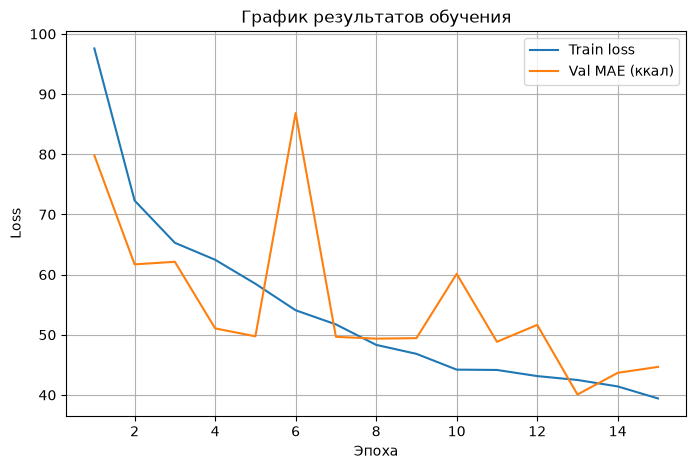

In [21]:
plt.figure(figsize=(8, 5))

x = range(1, len(history["train_loss"]) + 1)

plt.plot(x, history["train_loss"], label="Train loss")
plt.plot(x, history["val_mae"], label="Val MAE (ккал)")

plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("График результатов обучения")

plt.legend()
plt.grid(True)
plt.show()

По графику видно, что train_loss продолжает снижаться даже после 15 эпох. Значение MAE на валидационной части изменяется в обе стороны, но в целом тренд на снижение. Для финальной оценки качества будем использовать результат по MAE на валивационной части около 40 ккал.


## Валидация качества


Загружаем лучшую модель из предварительно сохранённого чекпоинта и проверяем метрику MAE на тестовой выборке.


In [22]:
model = DishCaloriesRegressor.from_config(config).to(device)
model.load_state_dict(
    torch.load(Path(config.CHECKPOINTS_DIR) / "best_model.pt", map_location=device)
)

test_mae, results = validate(model, test_loader, device, report_all_results=True)
print(f"MAE на тестовой выборке: {test_mae:.4f} ккал")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

MAE на тестовой выборке: 46.0503 ккал


MAE на тестовой выборке получился около 46 ккал, что удовлетворяет требованиям к значению целевой метрики.


In [23]:
results["mae"] = abs(results["pred"] - results["target"])

top_mae_error = (
    results
    .sort_values("mae", ascending=False)
    .head(5)
    .reset_index(drop=True)
)
top_mae_error

,dish_id,pred,target,mae
0,dish_1558720236,515.230896,887.823059,372.592163
1,dish_1558549806,483.851532,781.958008,298.106476
2,dish_1563478751,672.595459,950.395081,277.799622
3,dish_1558372948,412.412201,687.939026,275.526825
4,dish_1558630325,484.090027,751.541992,267.451965


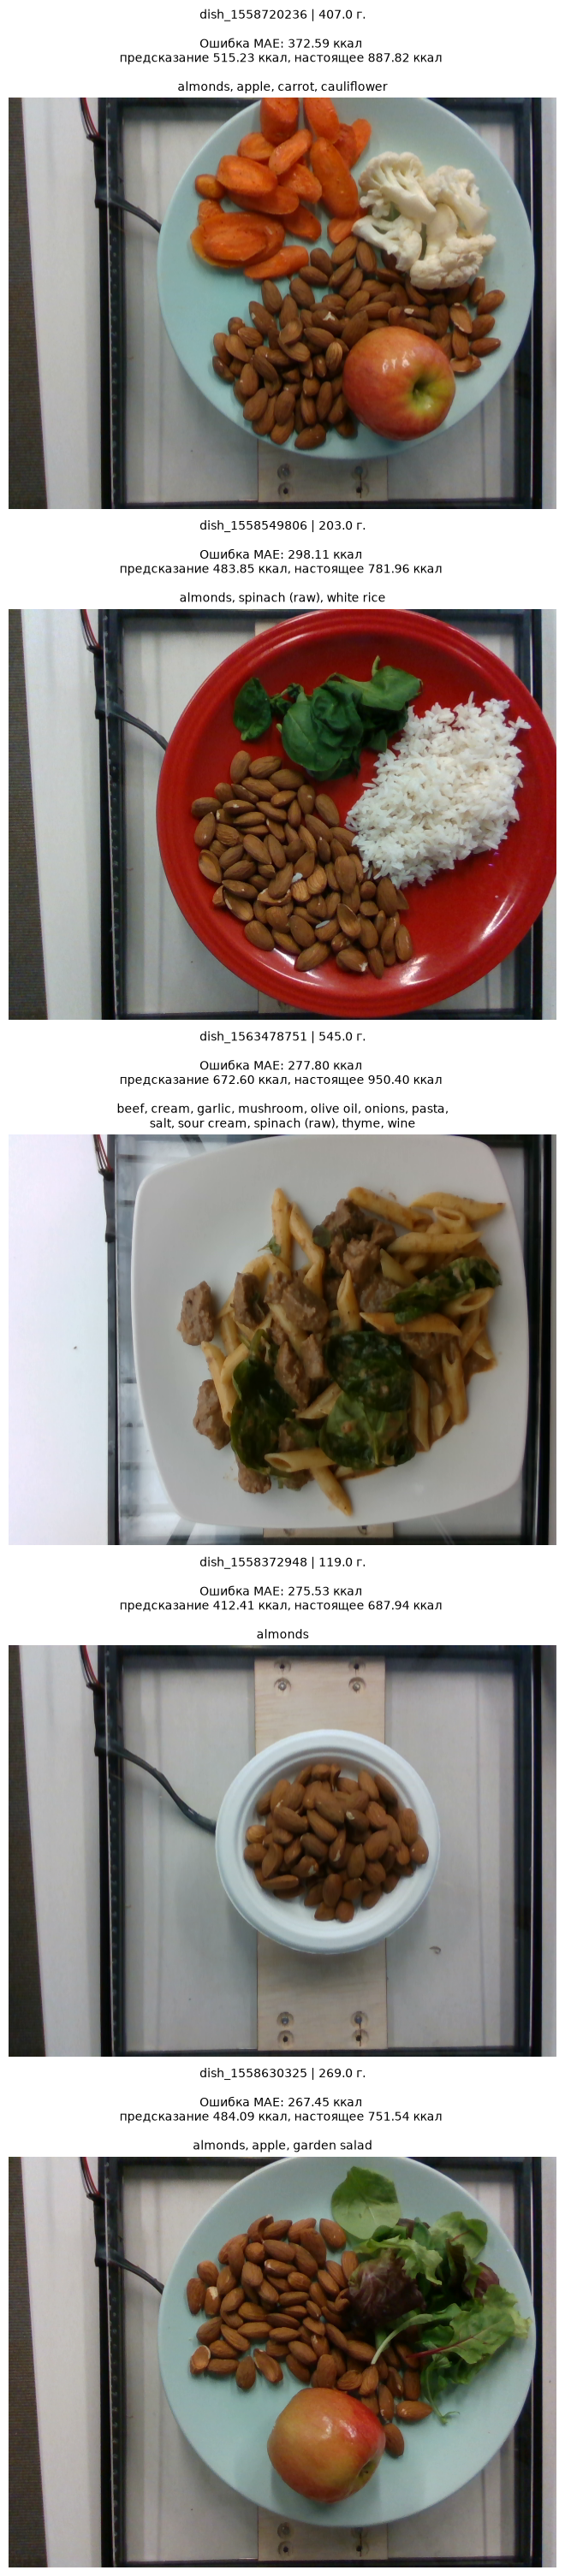

In [24]:
_, axes = plt.subplots(5, 1, figsize=(16, 30), layout="constrained")

axes = axes.flatten()

for i, item in top_mae_error.iterrows():
    dish_id = item["dish_id"]

    img = load_dish_image(dish_id, config.DATA_DIR)
    total_mass, ingredients = dishes_df.loc[
        dish_id, ["total_mass", "ingredients"]
    ]
    pred_total_calories, target_total_calories, mae = item[["pred", "target", "mae"]]

    axes[i].imshow(img)
    axes[i].axis("off")

    title = (
        f"{dish_id} | {total_mass} г.\n\n"
        f"Ошибка MAE: {mae:.2f} ккал \n"
        f"предсказание {pred_total_calories:.2f} ккал, настоящее {target_total_calories:.2f} ккал \n\n"
        f"{"\n".join(textwrap.wrap(ingredients, width=60))}"
    )
    axes[i].set_title(title, fontsize=10)

plt.show()

В 4 из 5 блюд с наибольшей ошибкой предсказание есть миндаль - довольно калорийный продукт. Похоже, что модель часто недооценивает его вклад в общую калорийность. Это выглядит как систематическая проблема, т.к. в исходных данных нет информации о средней калорийности ингредиентов. Модель не может "узнать", что именно миндаль даёт основную калорийность, а не другие ингредиенты - например, овощи и фрукты, как в примерах. 

Также, в составе блюд не указана масса/количество для каждого из ингредиентов. Думаю, это бы помогло уменьшить ошибку на блюдах, где калорийные ингредиенты (оливковое масло, курица, говядина) недооцениваются моделью, т.к. содержатся в блюдах со множеством других низкокалорийных (например, салаты как основное блюдо).

Вообще, при обучении использовался `L1Loss`, поэтому можно сказать, что модель выучивает медианные значения. Из-за этого для блюд с высокой калорийностью, которые нечасто встречаются в выборке, предсказанное значение будет более консервативным (ближе к медиане).

Для дальнейшего улучшения метрики MAE можно:
- поучить модель ещё несколько эпох, возможно, минимум для MAE на валидационной выборке не был достигнут,
- применить другую функцию потерь, к примеру, Huber Loss (L2 вместо L1 для больших ошибок),
- использовать адаптивный learning rate,
- попробовать другие аугментации для изображений.